# Filtros lineares

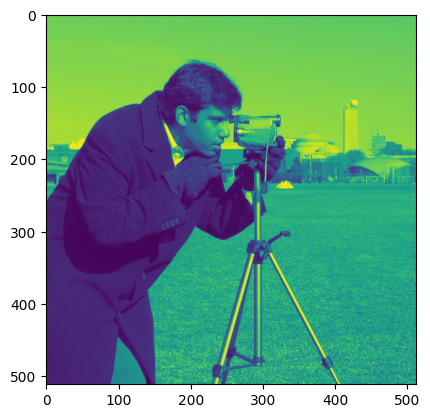

In [ ]:
from PIL import Image
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

def image():
  try:
    # Tenta abrir a imagem do caminho especificado
    pil_image = Image.open('/content/caneca-1.jpeg')
    # Converte a imagem PIL para escala de cinza ('L' para Luminância)
    pil_image_grayscale = pil_image.convert('L')
    # Converte a imagem PIL em escala de cinza para um array NumPy
    img_array = np.array(pil_image_grayscale)
    # Garante que o tipo de dado seja uint8
    img_array = img_array.astype(np.uint8)
    return img_array
  except FileNotFoundError:
    return data.camera()
  except Exception as e:
    return data.camera()

plt.imshow(image())

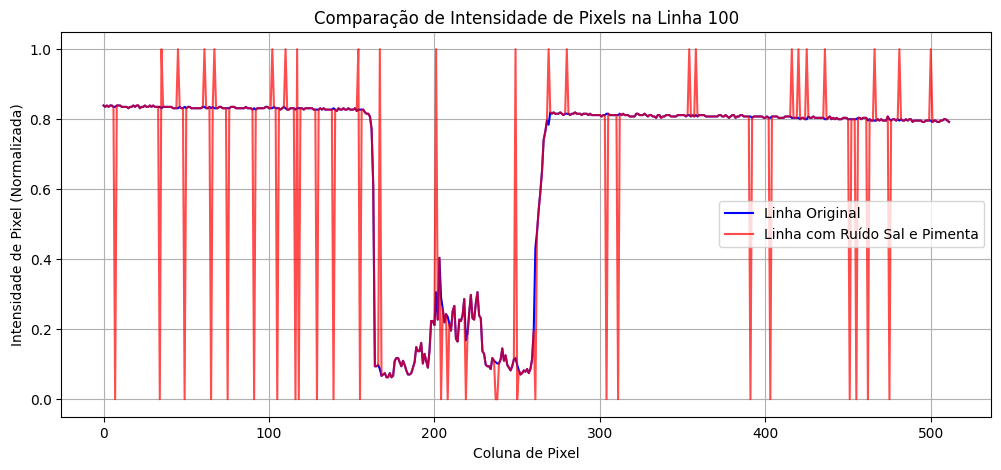

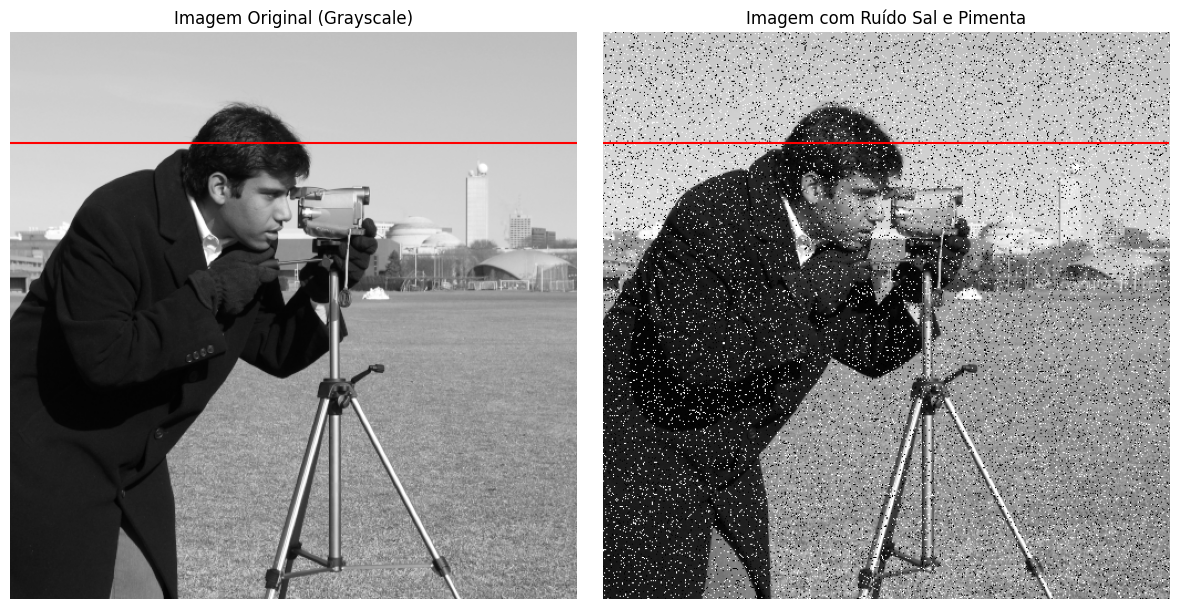

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
from skimage.color import rgb2gray

# Função gera ruído do notebook anterior
def gera_ruido(original, noise_type="gaussian", noise_level=0.02):
    # Verifica se a imagem é nível de cinzas
    if len(original.shape) == 3:
        grayscale = rgb2gray(original)
    else:
        grayscale = original

    # --- Adiciona ruído gaussiano, ou sal e pimenta ---
    if noise_type == "gaussian":
        noise = np.random.normal(0, noise_level, grayscale.shape)
        grayscale_ruido = grayscale + noise
    else: # "salt_pepper"
        grayscale_ruido = grayscale.copy()
        p = noise_level  # fração de pixels afetados

        # máscaras aleatórias
        rnd = np.random.rand(*grayscale.shape)
        grayscale_ruido[rnd < p / 2] = 0      # pimenta
        grayscale_ruido[rnd > 1 - p / 2] = 1  # sal

    # Garante faixa dinâmica válida
    grayscale_ruido = np.clip(grayscale_ruido, 0, 1)
    return(grayscale_ruido)

def main():
  # Carrega uma imagem
  original_image = image()

  # Normaliza para 0-1
  grayscale_original = original_image / 255.0

  # Gera ruído sal e pimenta
  noisy_image_sp = gera_ruido(grayscale_original, noise_type="salt_pepper", noise_level=0.1)

  # Vamos escolher uma linha
  row_index = 100

  # Extrai a linha das imagens com e sem ruído
  originalRow = grayscale_original[row_index, :]
  noisyRow = noisy_image_sp[row_index, :]

  # Plot the pixel intensities of the selected rows
  plt.figure(figsize=(12, 5))
  plt.plot(originalRow, label='Linha Original', color='blue')
  plt.plot(noisyRow, label='Linha com Ruído Sal e Pimenta', color='red', alpha=0.7)
  plt.title(f'Comparação de Intensidade de Pixels na Linha {row_index}')
  plt.xlabel('Coluna de Pixel')
  plt.ylabel('Intensidade de Pixel (Normalizada)')
  plt.legend()
  plt.grid(True)
  plt.show()

  # Display the full images for context (optional)
  plt.figure(figsize=(12, 6))

  plt.subplot(1, 2, 1)
  plt.imshow(grayscale_original, cmap='gray')
  plt.axhline(y=row_index, color='r', linestyle='-') # Highlight the selected row
  plt.title('Imagem Original (Grayscale)')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(noisy_image_sp, cmap='gray')
  plt.axhline(y=row_index, color='r', linestyle='-') # Highlight the selected row
  plt.title('Imagem com Ruído Sal e Pimenta')
  plt.axis('off')

  plt.tight_layout()
  plt.show()

main()

# Exercício: Implemente uma função que aplique o filtro da média para um kernel de 3 pontos. Sua função deve receber uma linha de uma imagem e retornar uma nova linha com o resultado do filtro da média de três pontos.

In [ ]:
# Para cada linha, apresente o gráfico como no exemplo acima
def plotar(originalRow, filtered_image, label=['', '']):
  plt.figure(figsize=(12, 5))
  plt.plot(originalRow, label=label[0], color='blue')
  plt.plot(filtered_image, label=label[1], color='red', alpha=0.7)
  plt.title(f'Comparação de Intensidade de Pixels na Linha')
  plt.xlabel('Coluna de Pixel')
  plt.ylabel('Intensidade de Pixel (Normalizada)')
  plt.legend()
  plt.grid(True)
  plt.show()

def image_plot(original, filtered_image, row_index=1, title=['','']):
  # Display the full images for context (optional)
  plt.figure(figsize=(12, 6))

  plt.subplot(1, 2, 1)
  plt.imshow(original, cmap='gray')
  plt.axhline(y=row_index, color='r', linestyle='-') # Highlight the selected row
  plt.title(title[0])
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(filtered_image, cmap='gray')
  plt.axhline(y=row_index, color='r', linestyle='-') # Highlight the selected row
  plt.title(title[1])
  plt.axis('off')

  plt.tight_layout()
  plt.show()

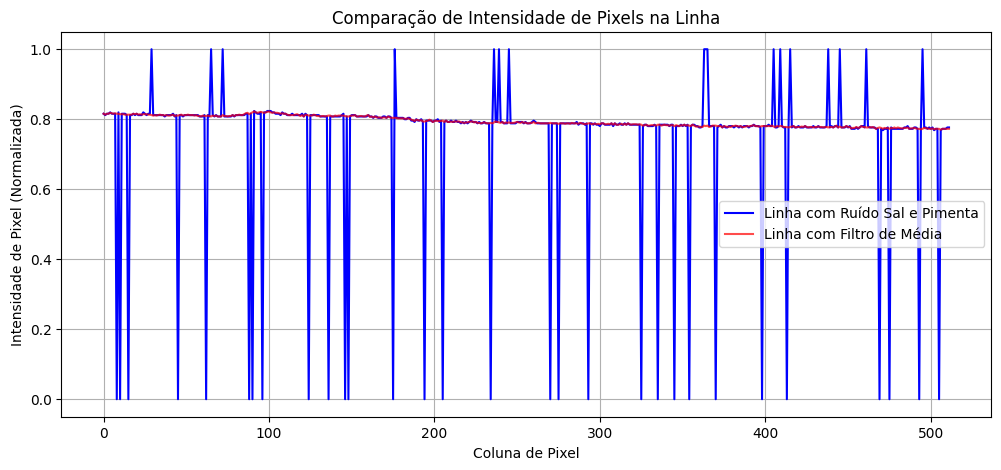

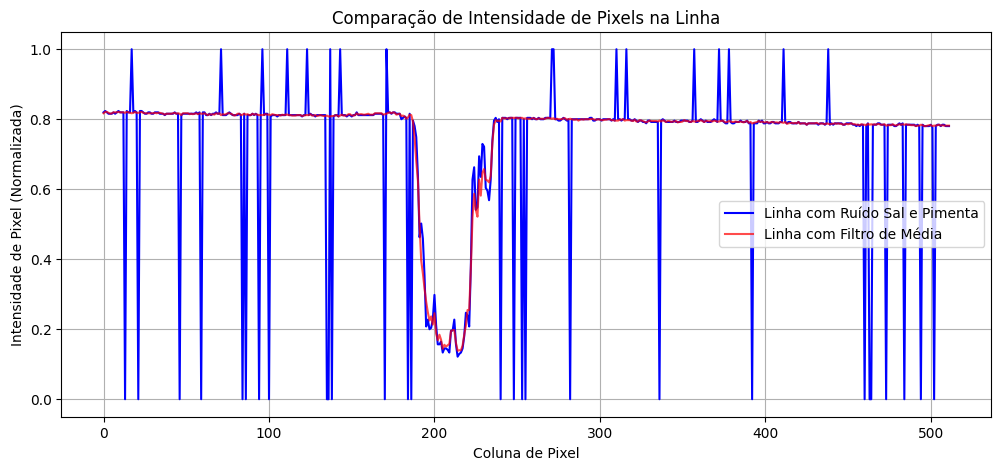

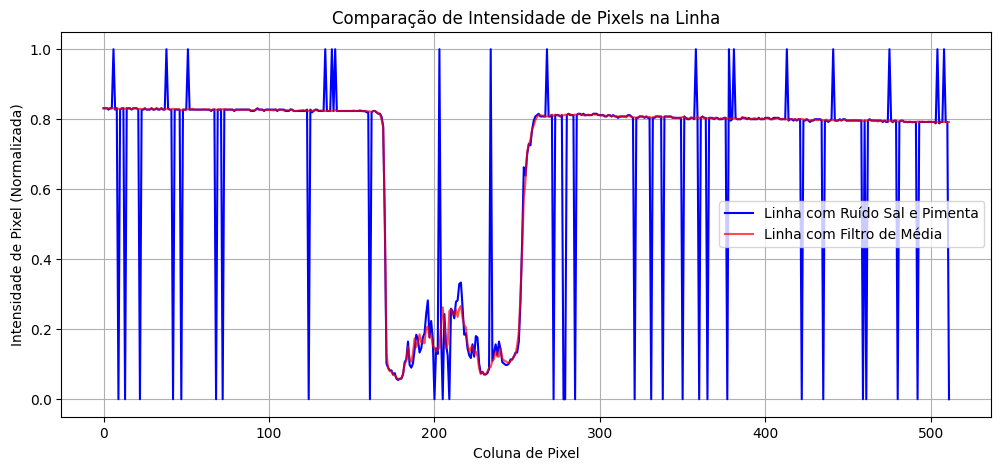

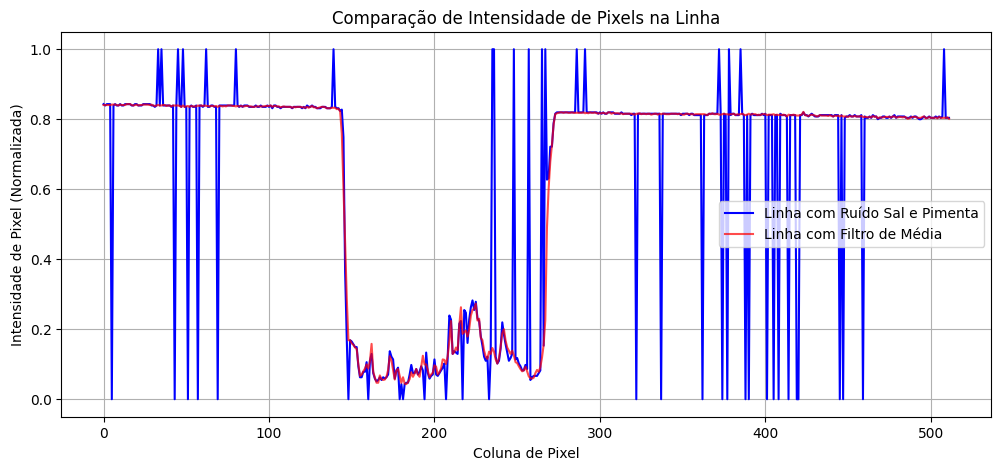

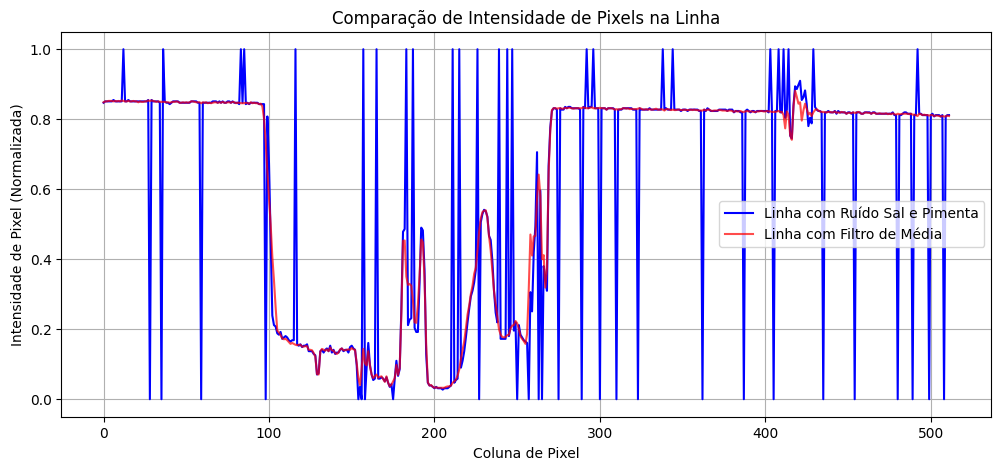

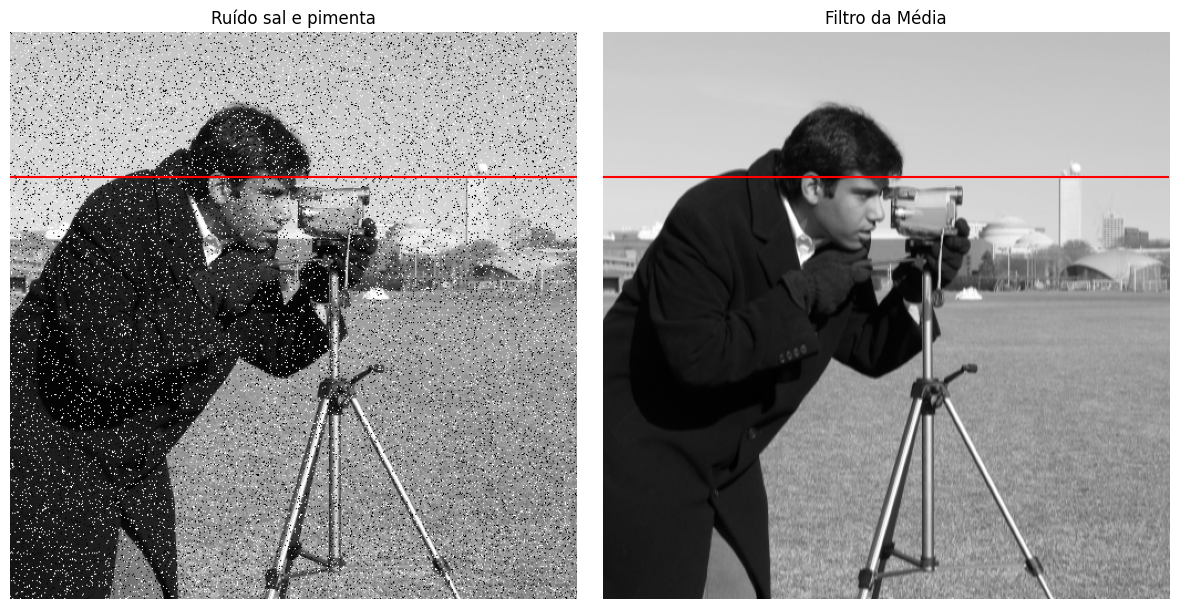

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def filtroMedia3pontos(rowData):
    # Cria uma cópia do tipo float para guardar o resultado
    # dica, use np.copy
    resultado = np.copy(rowData).astype(float)

    # Aplique o filtro da média usando for
    # Dica, comece do segundo até o penúltimo elemento do vetor
    for i in range(1, len(rowData)-1):
      resultado[i] = (rowData[i-1] + rowData[i] + rowData[i+1])/3

    return resultado

# Faça uma função main que chame a função criada para cinco
# linhas arbitrárias e retorne o resultado
def main():
  # Carrega uma imagem
  original_image = image()

  # Normaliza para 0-1
  grayscale_original = original_image / 255.0

  # Gera ruído sal e pimenta
  noisy_image_sp = gera_ruido(grayscale_original, noise_type="salt_pepper", noise_level=0.1)

  # Gera filtro de média com kernel de 3 pontos
  filtered_image = filtroMedia3pontos(grayscale_original)

  for i in range(50, 150, 20):
    # Seleciona as linhas das imagens original e com filtro
    noisyRow = noisy_image_sp[i, :]
    filteredRow = filtered_image[i, :]
    # Chama as funções de de plotagem para os gráficos e imagens por indíce
    plotar(noisyRow, filteredRow, label=['Linha com Ruído Sal e Pimenta', 'Linha com Filtro de Média'])

  image_plot(noisy_image_sp, filtered_image, row_index=i, title=['Ruído sal e pimenta', 'Filtro da Média'])


main()


Exercício: Repita o exercício para um kernel de cinco pontos.

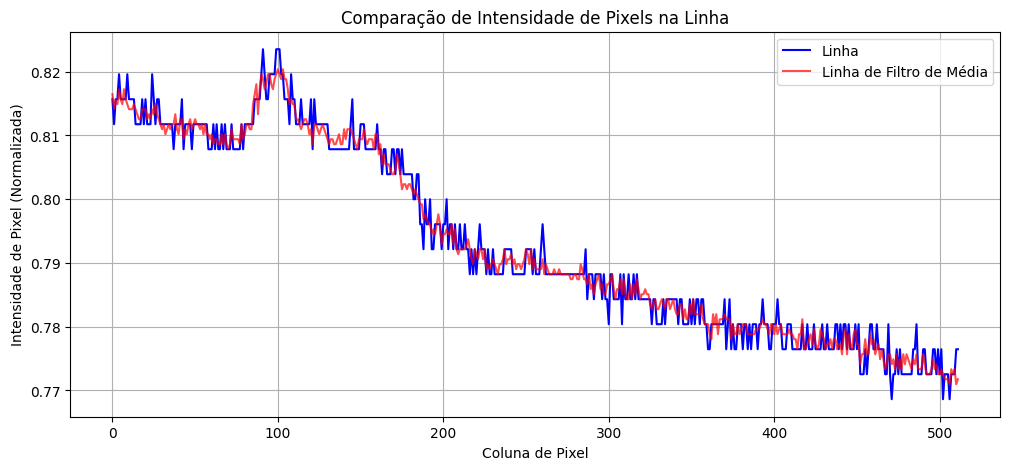

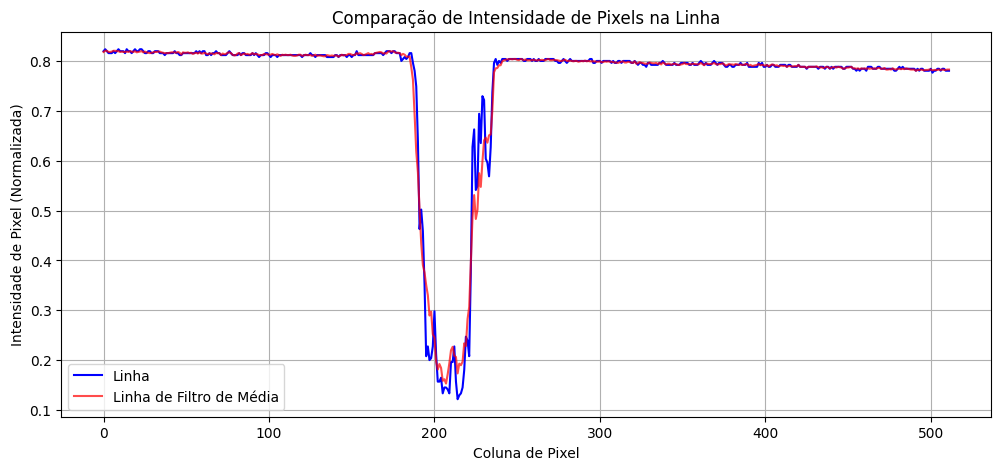

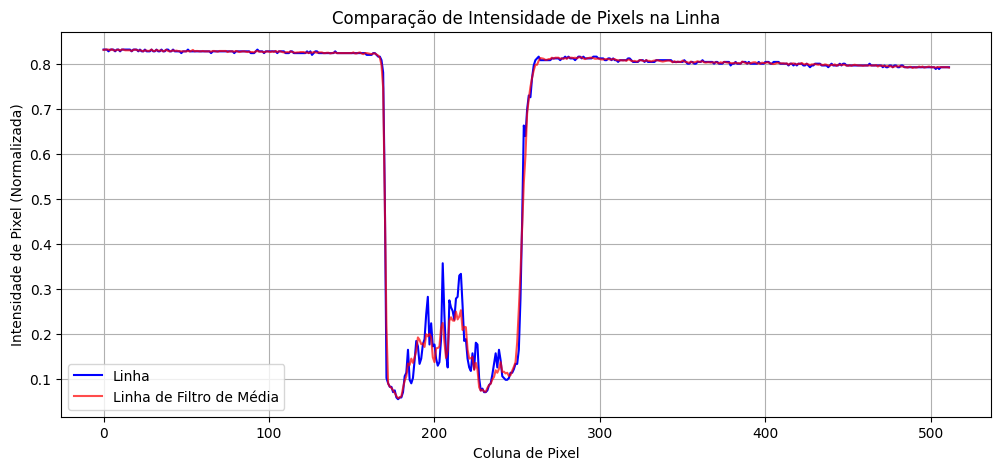

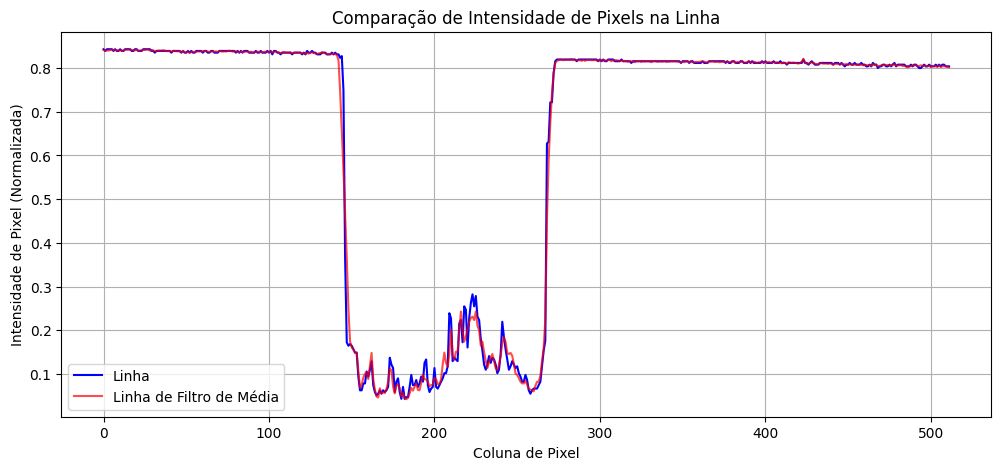

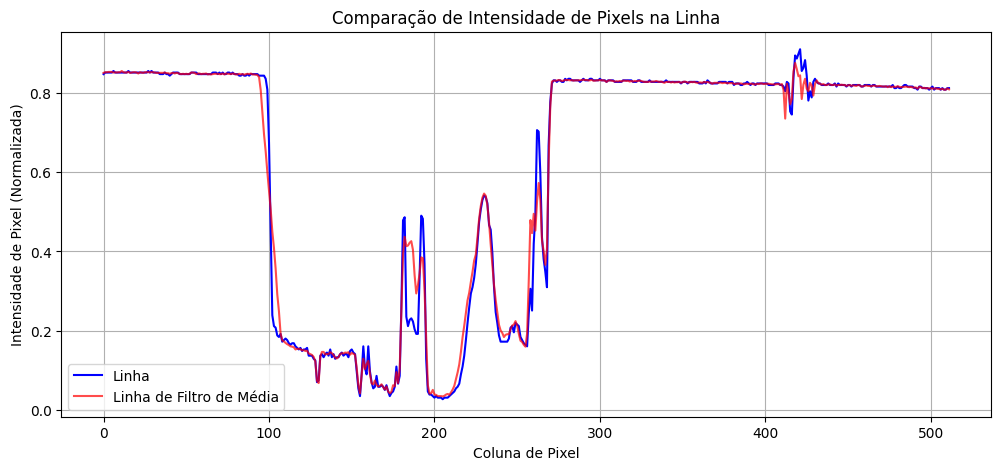

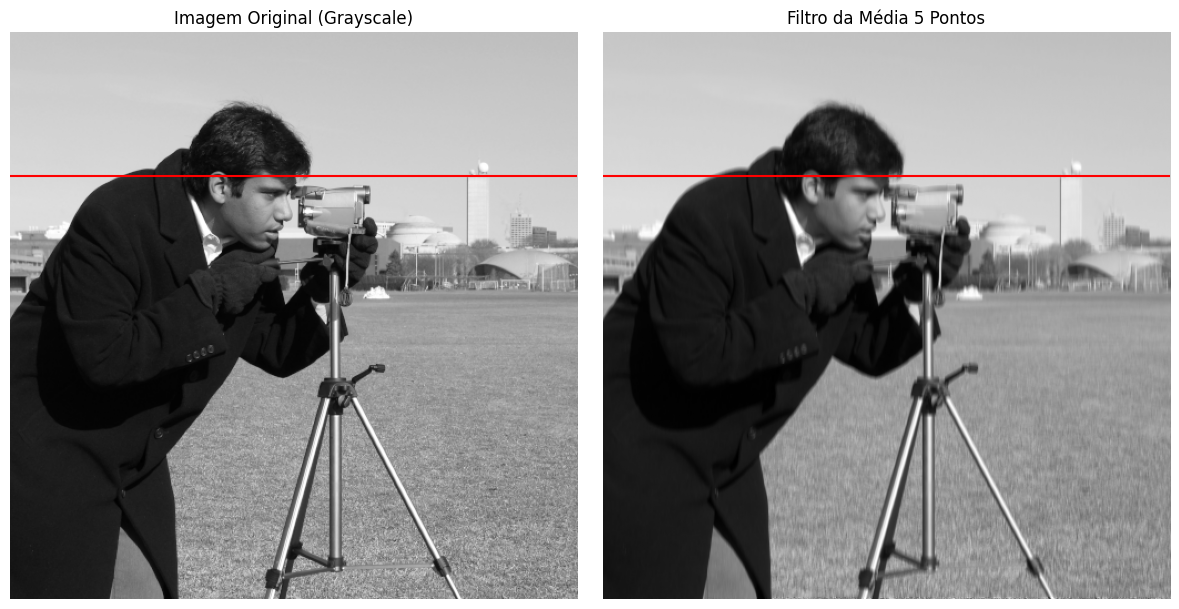

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def filtroMedia5pontos(rowData):
    # Cria uma cópia do tipo float para guardar o resultado
    resultado = np.copy(rowData).astype(float)

    # Aplique o filtro da média usando for
    # Para um kernel de 5 pontos, precisamos de 2 vizinhos de cada lado.
    # Então, o loop deve ir de índice 2 até len(rowData) - 2.
    for i in range(2, len(rowData)-2):
      resultado[i] = (rowData[i-2] + rowData[i-1] + rowData[i] + rowData[i+1] + rowData[i+2])/5

    return resultado

# Faça uma função main que chame a função criada para cinco
# linhas arbitrárias e retorne o resultado
def main():
  # Carrega uma imagem
  original_image = image()

  # Normaliza para 0-1
  grayscale_original = original_image / 255.0

  filtered_image = filtroMedia5pontos(grayscale_original)

  for i in range(50, 150, 20):
    # Seleciona as linhas das imagens original e com filtro
    noisyRow = grayscale_original[i, :]
    filterRow = filtered_image[i, :]
    # Chama as funções de plotagem para os gráficos e imagens por indíce
    plotar(noisyRow, filterRow, label=['Linha', 'Linha de Filtro de Média'])


  image_plot(grayscale_original, filtered_image, row_index=i, title=['Imagem Original (Grayscale)', 'Filtro da Média 5 Pontos'])

main()

# Exercício: Aplique o filtro de três pontos em todas as linhas da imagem e compare com o resultado da média das imagens da aula anterior.

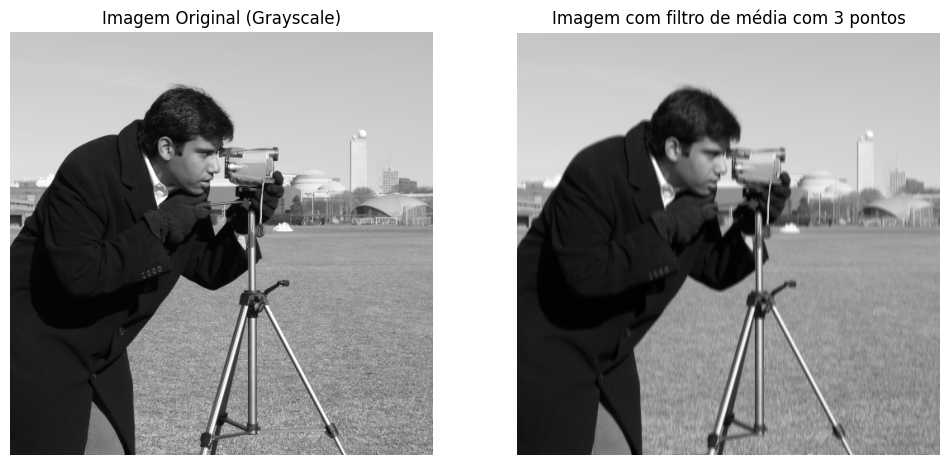

In [ ]:
# Carrega uma imagem
original_image = image()

# Normaliza para 0-1
grayscale_original = original_image / 255.0

filtered_image = filtroMedia5pontos(grayscale_original)

resultado = []

for i in range(len(filtered_image)-1):
  filterRow = filtered_image[i, :]
  resultado.append(filterRow)

resultado = np.array(resultado)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(grayscale_original, cmap='gray')
plt.title('Imagem Original (Grayscale)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(resultado, cmap='gray')
plt.title('Imagem com filtro de média com 3 pontos')
plt.axis('off')

plt.show()
